# 1. Tile embeddings

This tutorial computes tile-level embeddings from an H&E slide and shows how to inspect, save, and
explore them.

> **This tutorial teaches**
>
> - **Task:** compute and explore tile-level representations
> - **Required input:** an H&E image source
> - **Output:** `TileEmbeddings`
> - **Example used here:** a whole-slide image loaded with `read_slide()`
> - **Key concept:** one embedding per tissue tile, with spatial coordinates when available

```text
image source  →  encode_tiles()  →  TileEmbeddings
```

Other supported image formats use the same downstream workflow. See [Images](../../inputs/images/).

Set the paths in the first code cell, then run the notebook from top to bottom. See
[Tile embeddings](../../outputs/tile-embeddings/) for the complete description of the result
object.

> **Example outputs.** The outputs shown in this tutorial come from the H&E image of the 10x Genomics
> *FFPE Human Breast with Custom Add-on Panel* dataset, an OME-TIFF file named `slide.ome.tif` here.
> `REGION` selects a 2.3 mm region of it.
>
> Source: [FFPE Human Breast with Custom Add-on Panel](https://www.10xgenomics.com/datasets/ffpe-human-breast-with-custom-add-on-panel-1-standard), 10x Genomics,
> [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

In [1]:
from pathlib import Path

import numpy as np

import alhena
from alhena import io

# Optional model configuration.
BACKBONE = None  # UNI2-h weights; None uses ALHENA's standard lookup
BUNDLE = None    # local encoder bundle; None uses the standard ALHENA resource
DEVICE = None    # None selects an available CUDA device when possible

# The slide to read.
SLIDE = Path("slide.ome.tif")

# Optional slide region: (x0, y0, x1, y1) in full-resolution pixels.
# The example region; set to None to use all tiles.
REGION = (30912, 37184, 41664, 47936)

# Where the results are written. Tutorials 2 to 4 read from the same folder.
OUT = Path("alhena_out")
OUT.mkdir(exist_ok=True)

print(alhena.__version__)

0.1.0


## Read the slide

`read_slide()` creates a tile source and reads the physical resolution from the slide metadata.
Tiles are then read on demand rather than loading the entire slide into memory.

In [2]:
slide = io.read_slide(SLIDE)
tile_px = slide.tile_shape[0]

print(slide.mpp, "micron per pixel, read from", slide.mpp_source)
print(len(slide), "tiles of", tile_px, "pixels, each covering", round(tile_px * slide.mpp, 1), "micron")
print("tile origins are written in:", slide.coords_frame)

0.2125 micron per pixel, read from OME PhysicalSizeX
13189 tiles of 448 pixels, each covering 95.2 micron
tile origins are written in: slide.ome.tif, level 0


## Check the image geometry

`describe_geometry()` shows how an input tile maps onto the model field of view. With the default
tile size selected by `read_slide()`, little or no padding or cropping should be required.

See [Geometry](../../concepts/geometry/).

In [3]:
report = alhena.describe_geometry(mpp=slide.mpp, tile_size_px=tile_px)

print("field of view", report.field_of_view_um, "micron")
print("white pad", report.pad_fraction, "| cropped away", report.crop_fraction)
for note in report.warnings:
    print(note)

field of view 95.2 micron
white pad 0.0 | cropped away 0.0


## Choose the tiles

`read_slide()` does not perform tissue detection, so a full slide grid can include background
regions.

This example optionally restricts the analysis to `REGION`: `region=` keeps only the tiles lying
wholly inside it. If tissue regions have already been selected by another tool, their tile origins
can instead be passed through `coords=`. See
[Choosing which tiles](../../inputs/images/#choosing-which-tiles).

In [4]:
source = io.read_slide(SLIDE, region=REGION)

print(len(source), "tiles to encode")

576 tiles to encode


## Load the encoder

`load_encoder()` loads the UNI2-h image encoder together with the ALHENA adaptation and projection
components.

In [5]:
encoder = alhena.load_encoder(backbone=BACKBONE, bundle=BUNDLE, device=DEVICE)

## Encode the tiles

`encode_tiles()` processes the tile source and returns one tile-level embedding per input tile.

In [6]:
tiles = encoder.encode_tiles(source)

### When tiles are already in memory (optional)

A whole-slide image is only one way to supply tiles. If another tool has already extracted image
patches, `read_tiles()` wraps them in the same type of input used by `encode_tiles()`.

Here, a few tiles from the current image illustrate that the encoding step stays the same. Passing
their origins through `coords=` preserves their spatial positions. For independent patches without
known positions, omit `coords=`.

See [Tiles already cut](../../inputs/images/#tiles-already-cut) for image folders and HDF5 files.

In [7]:
# Four tiles held in memory, as another tool would return them.
patches = np.stack([source[i] for i in range(4)])
patch_source = io.read_tiles(patches, mpp=slide.mpp, coords=source.coords[:4])
patch_embeddings = encoder.encode_tiles(patch_source)

print(len(patch_embeddings), "tiles encoded | spatial bounds available:",
      patch_embeddings.bounds is not None)

4 tiles encoded | spatial bounds available: True


## Inspect the result

Each row of `TileEmbeddings` represents one tile.

- `embeddings` contains the 1536-dimensional pre-projection tile representations.
- `tile_ids` contains the tile identifiers.
- `bounds` contains `(x0, y0, x1, y1)` in source-image coordinates when spatial information is
  available.
- `centers` contains the center of each tile's spatial bounds.
- `bounds_mpp` gives the physical scale of these coordinates.
- `purpose="tiles"` identifies this as a dedicated tile-level encoding rather than tile context
  generated during cell encoding.

In [8]:
print("embeddings", tiles.embeddings.shape, tiles.embeddings.dtype)
print("names", tiles.tile_ids[:3])
print("spatial bounds, x0 y0 x1 y1:")
print(tiles.bounds[:3])
print("frame:", tiles.bounds_frame, "| micron per unit:", tiles.bounds_mpp)

embeddings (576, 1536) float32
names ('x30912_y37184', 'x31360_y37184', 'x31808_y37184')
spatial bounds, x0 y0 x1 y1:
[[30912. 37184. 31360. 37632.]
 [31360. 37184. 31808. 37632.]
 [31808. 37184. 32256. 37632.]]
frame: slide.ome.tif, level 0 | micron per unit: 0.2125


## Convert to AnnData

`to_anndata()` creates an analysis-ready table with one observation per tile:

- `obsm["X_alhena_tile"]` contains the tile embeddings;
- `obsm["spatial"]` contains tile centers when spatial coordinates are available;
- `obs` contains tile metadata and spatial bounds;
- `uns["alhena_tiles"]` contains encoding provenance.

`X` is empty because the embedding dimensions are representation features rather than measured
variables such as genes.

See [As an AnnData table](../../outputs/tile-embeddings/#as-an-anndata-table).

In [9]:
table = tiles.to_anndata()

print(table)
table.obs.head()

AnnData object with n_obs × n_vars = 576 × 0
    obs: 'tile_id', 'alhena_tile_index', 'alhena_tile_x0', 'alhena_tile_y0', 'alhena_tile_x1', 'alhena_tile_y1'
    uns: 'alhena_tiles'
    obsm: 'X_alhena_tile', 'spatial'
    layers: None (.X)


,tile_id,alhena_tile_index,alhena_tile_x0,alhena_tile_y0,alhena_tile_x1,alhena_tile_y1
x30912_y37184,x30912_y37184,0,30912.0,37184.0,31360.0,37632.0
x31360_y37184,x31360_y37184,1,31360.0,37184.0,31808.0,37632.0
x31808_y37184,x31808_y37184,2,31808.0,37184.0,32256.0,37632.0
x32256_y37184,x32256_y37184,3,32256.0,37184.0,32704.0,37632.0
x32704_y37184,x32704_y37184,4,32704.0,37184.0,33152.0,37632.0


## Save and reload

`write_h5ad()` preserves the complete tile table. `read_tile_embeddings()` reconstructs the
corresponding `TileEmbeddings`, including its spatial metadata, purpose, and encoding geometry.

In [10]:
tiles.write_h5ad(OUT / "tiles.h5ad")

reloaded = io.read_tile_embeddings(OUT / "tiles.h5ad")

## Explore the embedding space

As a simple preview of Tutorial 4, build a nearest-neighbor graph from `X_alhena_tile`, visualize
it with UMAP, and cluster the embeddings with Leiden.

These clusters are **tile embedding clusters**. They describe unsupervised structure in the ALHENA
representation and are not predefined tissue classes.

This cell requires Scanpy and igraph: `pip install scanpy igraph`.

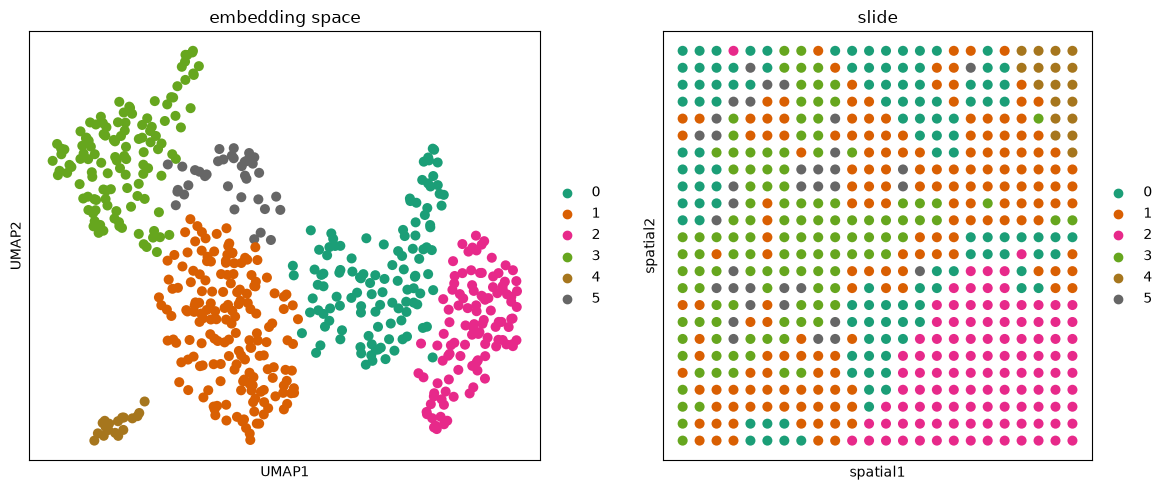

In [11]:
import matplotlib.pyplot as plt
import scanpy as sc

sc.pp.neighbors(table, use_rep="X_alhena_tile")
sc.tl.umap(table)
sc.tl.leiden(table, key_added="tile_cluster", resolution=0.5, flavor="igraph", n_iterations=2)

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.umap(table, color="tile_cluster", palette="Dark2", ax=axes[0], show=False,
           title="embedding space")
sc.pl.embedding(
    table,
    basis="spatial",
    color="tile_cluster",
    ax=axes[1],
    show=False,
    title="slide",
)
axes[1].invert_yaxis()
axes[1].set_aspect("equal")
figure.tight_layout()

## Where next

The tile embeddings are now saved in `OUT`.

[Tutorial 2](../02_cell_embeddings/) computes cell-level representations from the same slide, and
[Tutorial 4](../04_multiscale_analysis/) combines tile embeddings, cell embeddings, and cell-type
annotations for multi-scale analysis.

---

**Next:** [2. Cell embeddings](../02_cell_embeddings/)